# Week 2 · Logistic regression in class

**Two 90-minute sessions · predict → experiment → explain**

Follow the [worksheet](worksheet.md) for timing and complete questions. It selects short
experiments from the book's [Sections 8–10](https://healthml.github.io/deep-learning-book/chapters/02-linear-classification/concepts.html).
The complete lab remains after-class practice. Work in pairs: driver runs the experiment,
explainer predicts and interprets; swap after every lettered task. Keep each original
prediction next to the result. Complete exit tickets individually, without an assistant.

**All supplied cells run.** Write responses in **Your record** Markdown cells. Optional
implementation challenges do not block later cells. Run from this repository's uv
environment (`uv sync --locked --group notebook`). No book checkout or data download is needed.
**Run All does not open the test set:** the final cell is disabled by default.

**Fixed experiment:** `concavity_mean`, `texture_mean`; malignant=1, benign=0;
`theta=(b,w_concavity,w_texture)`; book split seed 8 (341/113/115); mean BCE;
float64 CPU, full batches, initial scores zero; training-only scaling.
This historical teaching dataset does not constitute a clinical diagnostic system.


In [2]:
import inspect
import numpy as np
import matplotlib.pyplot as plt
from dlexercises.week02 import (
    binary_metrics, design, fit_penalized, gradient, gradient_descent,
    hessian, load_wdbc, loss, newton, sigmoid, stratified_split,
)

# Explicit light figure canvas remains readable in light or dark notebook interfaces.
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white",
                     "text.color": "#202020", "axes.labelcolor": "#202020",
                     "xtick.color": "#202020", "ytick.color": "#202020",
                     "font.size": 11, "figure.dpi": 110})

X_all, y_all = load_wdbc()
train, valid, test = stratified_split(y_all, seed=8)
X, y = X_all[train], y_all[train]
X_valid, y_valid = X_all[valid], y_all[valid]
A, A_valid = design(X), design(X_valid)
assert (len(train), len(valid), len(test)) == (341, 113, 115)
assert X.shape == (341, 2) and y.shape == (341,) and A.shape == (341, 3)
assert len(set(train) & set(valid)) == len(set(train) & set(test)) == len(set(valid) & set(test)) == 0
assert len(np.unique(np.r_[train, valid, test])) == 569
print("Ready: training 341, validation 113, reserved test 115. No test predictions inspected.")


Ready: training 341, validation 113, reserved test 115. No test predictions inspected.


## Session 1 · A. Score, probability, decision — 15 minutes

Opening: sketch a straight boundary in the **training data** below. What mistakes remain?
Why is always-benign accuracy not enough to describe finding malignant examples?

**Predict before the next computation.** For `theta=(-3,20,0.05)`, hand-calculate $z$,
$p=\sigma(z)$, and the decision at $\tau=0.5$ for `(0.1,20)` and `(0.04,14)`.
Our rule is $\hat y=\mathbf1[p\geq\tau]$, so state what happens at equality.
What changes if every parameter is multiplied by ten: boundary, decisions, probabilities, loss?


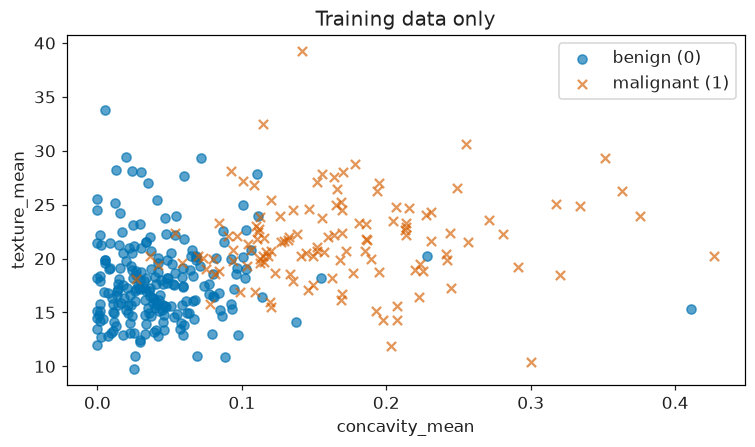

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for label, name, marker, color in [(0, "benign (0)", "o", "#0072B2"),
                                    (1, "malignant (1)", "x", "#D55E00")]:
    group = y == label
    ax.scatter(X[group, 0], X[group, 1], label=name, marker=marker, color=color, alpha=0.65)
ax.set(xlabel="concavity_mean", ylabel="texture_mean", title="Training data only")
ax.legend()
fig.tight_layout()
plt.show()


**Your record — A, before running:** sketch / two hand calculations / multiplier prediction.

_Write here._


Two toy rows: score / probability / decision at 0.5
[[ 0.          0.5         1.        ]
 [-1.5         0.18242552  0.        ]]
theta x  1: training loss=0.336735; accuracy=0.915
theta x 10: training loss=0.658806; accuracy=0.915
Training-prevalence baseline log loss: 0.660238
Always-benign training accuracy: 0.628


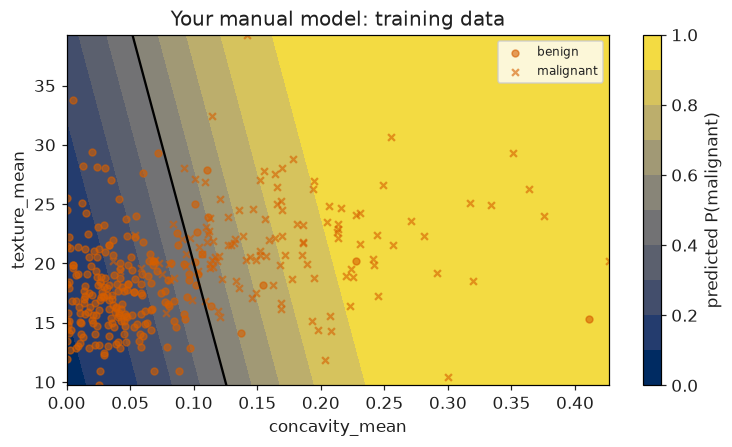

In [8]:
theta_try = np.array([-3.0, 20.0, 0.05]) * 1.0
toy_inputs = np.array([[0.1, 20.0], [0.04, 14.0]])
toy_scores = design(toy_inputs) @ theta_try
print("Two toy rows: score / probability / decision at 0.5")
print(np.column_stack((toy_scores, sigmoid(toy_scores), sigmoid(toy_scores) >= 0.5)))
q = y.mean()  # Training labels only.
p_baseline_train = np.full(len(y), q)
for multiplier in (1, 10):
    theta = multiplier * theta_try
    p = sigmoid(A @ theta)
    print(f"theta x {multiplier:2}: training loss={loss(A, y, theta):.6f}; accuracy={np.mean((p >= 0.5) == y):.3f}")
print(f"Training-prevalence baseline log loss: {binary_metrics(y, p_baseline_train)['log_loss']:.6f}")
print(f"Always-benign training accuracy: {np.mean(y == 0):.3f}")

# Visualize this manually chosen model; no optimizer is called in this task.
xx, yy = np.meshgrid(np.linspace(X[:, 0].min(), X[:, 0].max(), 120),
                     np.linspace(X[:, 1].min(), X[:, 1].max(), 120))
grid = np.column_stack((xx.ravel(), yy.ravel()))
grid_p = sigmoid(design(grid) @ theta_try).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7, 4.2))
shade = ax.contourf(xx, yy, grid_p, levels=np.linspace(0, 1, 11), cmap="cividis")
if grid_p.min() < 0.5 < grid_p.max():
    ax.contour(xx, yy, grid_p, levels=[0.5], colors="black", linewidths=1.5)
for label, marker, name in [(0, "o", "benign"), (1, "x", "malignant")]:
    group = y == label
    ax.scatter(X[group, 0], X[group, 1], marker=marker, color="#D55E00", s=20,
               alpha=0.6, label=name)
ax.set(xlabel="concavity_mean", ylabel="texture_mean", title="Your manual model: training data")
ax.legend(fontsize=8)
fig.colorbar(shade, ax=ax, label="predicted P(malignant)")
fig.tight_layout()
plt.show()


**Your record — A, after running:** explain what changed. Try at most three manual
parameter alternatives by editing `theta_try` above; record each reason and training loss.
Do not use validation or test for this manual demonstration.

| theta | reason | training loss | interpretation |
|---|---|---|---|
| your setting | | | |

**Support:** first find the sign of the score. **Extension:** derive the score boundary
for a threshold different from 0.5.


## B. Likelihood and log loss — 20 minutes

**Predict:** labels are `(1,0)`; two models give `(0.8,0.3)` and `(0.6,0.4)`.
Write each observed label's assigned probability, multiply, and compare likelihoods.
Do accuracies differ? Explain the path from $p^y(1-p)^{1-y}$ to mean negative log likelihood.

$$J=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]
=\frac1n\sum_i[\log(1+e^{z_i})-y_i z_i].$$

**Your record — B, before running:** calculations / why log and minus / mean versus sum.

_Write here._


Probabilities: [0.8 0.3] assigned: [0.8 0.7] likelihood: 0.5599999999999999 mean BCE: 0.2899092476264711
Probabilities: [0.6 0.4] assigned: [0.6 0.6] likelihood: 0.36 mean BCE: 0.5108256237659907


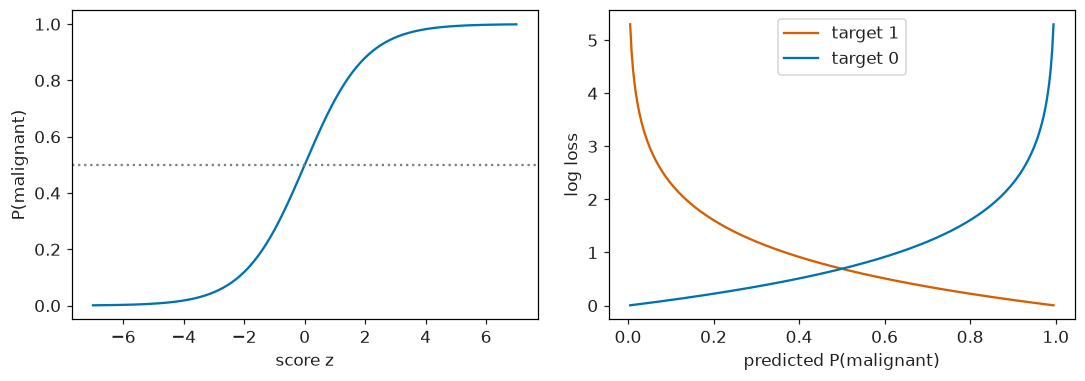

Confidently wrong extreme-score losses: [1000. 1000.]


In [4]:
toy_y = np.array([1.0, 0.0])
for toy_p in [np.array([0.8, 0.3]), np.array([0.6, 0.4])]:
    assigned = toy_p**toy_y * (1 - toy_p)**(1 - toy_y)
    print("Probabilities:", toy_p, "assigned:", assigned,
          "likelihood:", assigned.prod(), "mean BCE:", -np.log(assigned).mean())

scores = np.linspace(-7, 7, 300)
probabilities = np.linspace(0.005, 0.995, 300)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(scores, sigmoid(scores), color="#0072B2")
axes[0].axhline(0.5, color="0.5", linestyle=":")
axes[0].set(xlabel="score z", ylabel="P(malignant)")
axes[1].plot(probabilities, -np.log(probabilities), label="target 1", color="#D55E00")
axes[1].plot(probabilities, -np.log1p(-probabilities), label="target 0", color="#0072B2")
axes[1].set(xlabel="predicted P(malignant)", ylabel="log loss")
axes[1].legend()
fig.tight_layout()
plt.show()

extreme_scores = np.array([-1000.0, 1000.0])
extreme_labels = np.array([1.0, 0.0])
extreme_losses = np.logaddexp(0.0, extreme_scores) - extreme_labels * extreme_scores
assert np.isfinite(extreme_losses).all()
print("Confidently wrong extreme-score losses:", extreme_losses)


**Your record — B, after running:** connect confident errors to the loss plot. Explain
the bug in `BCEWithLogitsLoss()(sigmoid(logits), targets)` without executing buggy code.

_Write here._

**Support:** when y=0, the assigned probability is 1-p. **Extension:** derive the
logit-form expression algebraically. The inputs and observed labels stay fixed in MLE;
likelihood is a function of parameters, not a probability distribution over parameters.


## C. Reuse GD; diagnose slow fitting — 15 minutes

**Predict before running:** does a steadily decreasing loss establish that fitting is
nearly complete? Give two explanations for a poor fitted classifier and an intervention
that distinguishes unfinished optimization from insufficient model capacity.

The supplied full-batch GD uses zero parameters, 2,000 updates, and a conservative
curvature-based learning-rate rule. It is not an arbitrary step size chosen to fail.

**Your record — C, before running:** expected outcome / two explanations / predictions
for more steps, different feature units, and a different update rule.

_Write here._


Initial loss=0.693147; raw GD after 2000=0.304525
Raw theta (intercept first): [-5.86845479 21.07744611  0.17407384]


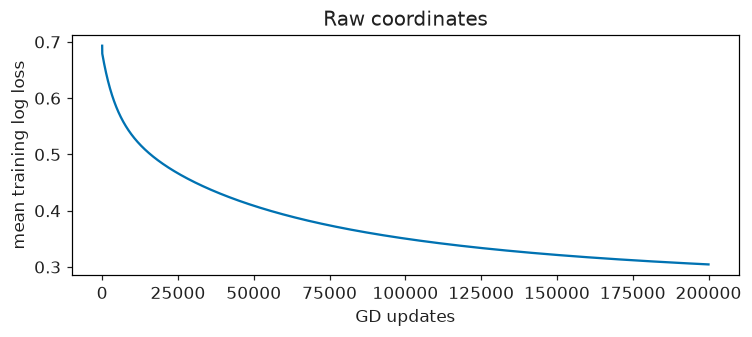

In [7]:
theta_raw, history_raw = gradient_descent(A, y, steps=200000)
print(f"Initial loss={history_raw[0]:.6f}; raw GD after 2000={history_raw[-1]:.6f}")
print("Raw theta (intercept first):", theta_raw)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(history_raw, color="#0072B2")
ax.set(xlabel="GD updates", ylabel="mean training log loss", title="Raw coordinates")
fig.tight_layout()
plt.show()


**Your record — C, after running:** observations and one proposed diagnostic.

_Write here._


## D. Derive, check, standardize — 22 minutes

For one observation, $\partial\ell/\partial z=p-y$ and
$\partial z/\partial(b,w_1,w_2)=(1,x_1,x_2)$.

1. At zero parameters, input `(0.1,20)`, target 1: write all three gradient
   contributions. Which way should a loss-reducing update move the score?
2. Explain $g=A^\top(p-y)/n$ and annotate shapes. What goes wrong if targets are `(n,1)`?
   Why not replace probabilities with thresholded predictions inside the gradient?
3. Predict derivative signs at raw `theta=(-1,3,0.03)`; compare central differences.
4. Predict what training-only standardization preserves and what it changes.

**Your record — D, before running:** one-example derivative / shapes / signs / prediction.

_Write here._


In [8]:
theta_probe_raw = np.array([-1.0, 3.0, 0.03])
eps, basis = 1e-5, np.eye(3)
g_fd = np.array([(loss(A, y, theta_probe_raw + eps * e) - loss(A, y, theta_probe_raw - eps * e)) / (2 * eps)
                 for e in basis])
g_analytic = gradient(A, y, theta_probe_raw)
np.testing.assert_allclose(g_analytic, g_fd, rtol=1e-6, atol=1e-7)
print("Analytic / finite-difference gradient:")
print(np.column_stack((g_analytic, g_fd)))

mu, scale = X.mean(axis=0), X.std(axis=0)  # Fit on TRAINING data only.
Z, Z_valid = (X - mu) / scale, (X_valid - mu) / scale
B, B_valid = design(Z), design(Z_valid)
np.testing.assert_allclose(Z.mean(axis=0), 0, atol=1e-14)
np.testing.assert_allclose(Z.std(axis=0), 1, atol=1e-14)
theta_scaled, history_scaled = gradient_descent(B, y, steps=2000)
theta_back = np.r_[theta_scaled[0] - (mu / scale) @ theta_scaled[1:], theta_scaled[1:] / scale]
np.testing.assert_allclose(A @ theta_back, B @ theta_scaled, atol=1e-12)
print("Training standard deviations:", scale)
print("Raw / standardized correlations:", np.corrcoef(X.T)[0, 1], np.corrcoef(Z.T)[0, 1])
print(f"Raw / standardized GD final training loss: {history_raw[-1]:.6f} / {history_scaled[-1]:.6f}")
print("Mapped parameters give equal logits.")


Analytic / finite-difference gradient:
[[ 0.08941821  0.08941821]
 [-0.0148782  -0.0148782 ]
 [ 1.06945857  1.06945857]]
Training standard deviations: [0.08053466 4.31389551]
Raw / standardized correlations: 0.34075653739845174 0.3407565373984516
Raw / standardized GD final training loss: 0.304525 / 0.262413
Mapped parameters give equal logits.


**Your record — D, after running:** derivative check and evidence for the original
slow-fit diagnosis. Why does standardizing validation separately change the model's
input coordinates? Distinguish an optimization observation from a generalization result.

_Write here._

**Support:** use the scalar derivative first. **Optional coding after class:** write
your own gradient and reproduce 100 NumPy GD updates in PyTorch with the same initial
parameters and learning rate. The supplied reference helper remains available.


## Session 1 · individual exit ticket — 8 minutes

Without code or an assistant:

1. Give two models with identical decisions and different likelihoods.
2. If target=1 and p=0.2, give the sign of the score derivative and the direction
   a loss-reducing update should move the score.
3. Name one quantity preserved by standardization and one that can change.

**My individual answers:** _Write here._

**Between sessions (about 30 minutes):** read the Newton section of Section 8,
annotate one Hessian entry, and rerun D with a three-sentence scaling explanation.
Section 10 is an optional mathematical depth route.


## Session 2 · E. Solve using curvature — 35 minutes

Retrieval launch: $f(u,v)=\tfrac12(4u^2+v^2)$ at `(1,2)`. Hand-calculate its gradient,
Hessian, and Newton step by solving $Hs=g$, then subtracting $s$. Compare one GD step
with $\eta=1/4$. How would a one-dimensional quadratic illustrate $u-f'(u)/f''(u)$?

For logistic loss, $H=A^\top\operatorname{diag}(p_i(1-p_i))A/n$.
Read the supplied functions below. Find the linear solve, the backtracking check,
and the internal stopping diagnostic. Why must curvature be recomputed?

**Your record — E, before running:** toy calculations / code annotations / comparison prediction.

_Write here._


In [ ]:
print(inspect.getsource(hessian))
print(inspect.getsource(newton))


**Fair comparison:** keep rows, labels, model family, mean unpenalized log loss,
and zero initial logits fixed. Each coordinate system uses the same GD step-size
**rule**. Newton may do more work per update. Compare all trajectories using the
first training loss gap to the stationary reference $\leq10^{-6}$, not by comparing
different stopping diagnostics. Failure to reach the target within the cap is a result.


In [ ]:
theta_mle, history_newton, step_sizes = newton(B, y)
theta_nt_raw, history_nt_raw, _ = newton(A, y)
reference = loss(B, y, theta_mle)
np.testing.assert_allclose(A @ theta_nt_raw, B @ theta_mle, atol=1e-8)
np.testing.assert_allclose(history_nt_raw, history_newton, atol=1e-12)
assert np.linalg.norm(gradient(B, y, theta_mle), ord=np.inf) < 1e-8
runs = {"GD, raw": history_raw, "GD, standardized": history_scaled,
        "Newton, raw": history_nt_raw, "Newton, standardized": history_newton}
print(f"Stationary reference training loss: {reference:.9f}")
for name, history in runs.items():
    reached = np.flatnonzero(history - reference <= 1e-6)
    first = str(reached[0]) if len(reached) else "not reached within 2000"
    print(f"{name:22s} final={history[-1]:.6f}; first update to common target={first}")
print("Newton accepted step sizes:", step_sizes)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax in axes:
    for name, history in runs.items():
        ax.semilogy(np.maximum(history - reference, 1e-12), label=name,
                    linestyle="--" if name == "Newton, standardized" else "-",
                    marker="o" if name.startswith("Newton") else None)
    ax.axhline(1e-6, linestyle=":", color="0.5")
    ax.set(xlabel="accepted parameter updates", ylabel="training loss minus reference")
axes[0].set_xlim(0, 2000)
axes[1].set_xlim(0, 120)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


**Controlled correlation intervention:** native concavity/texture correlation is moderate.
Now deliberately form $u=z_1$, $v=z_1+0.08z_2$ from standardized features. Predict:
can you recover the originals? Does the model family or best possible loss change?
What do you expect for GD and Newton? This is a new coordinate system, not a new diagnosis.

**Your record — E, before this intervention:** inverse map and predictions.

_Write here._


In [ ]:
transform = np.array([[1.0, 1.0], [0.0, 0.08]])
Z_correlated = Z @ transform
C = design(Z_correlated)
theta_gd_c, history_gd_c = gradient_descent(C, y, steps=2000)
theta_nt_c, history_nt_c, _ = newton(C, y)
np.testing.assert_allclose(C @ theta_nt_c, B @ theta_mle, atol=1e-8)
np.testing.assert_allclose(history_nt_c, history_newton, atol=1e-12)
print("Transformed column standard deviations:", Z_correlated.std(axis=0))
print("Transformed correlation:", np.corrcoef(Z_correlated.T)[0, 1])
for name, matrix in [("raw", A), ("standardized", B), ("deliberately correlated", C)]:
    print(name, "initial Hessian condition number:", np.linalg.cond(hessian(matrix, np.zeros(3))))
print("Standardized / correlated GD final gaps:", history_scaled[-1] - reference, history_gd_c[-1] - reference)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, features, title in [(axes[0], Z, "Standardized"), (axes[1], Z_correlated, "Correlated coordinates")]:
    ax.scatter(features[:, 0], features[:, 1], c=y, cmap="cividis", s=12, alpha=0.65)
    ax.set(title=title, xlabel="coordinate 1", ylabel="coordinate 2")
    ax.set_aspect("equal", adjustable="datalim")
for name, history in [("GD, standardized", history_scaled), ("GD, correlated", history_gd_c),
                      ("Newton, either", history_nt_c)]:
    axes[2].semilogy(np.maximum(history - reference, 1e-12), label=name)
axes[2].axhline(1e-6, color="0.5", linestyle=":")
axes[2].set(xlabel="accepted updates", ylabel="training loss gap")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()


**Your record — E, after running:** comparison table / evidence separating scale from
correlation / why equal fitted logits matter / why update counts do not establish
wall-clock speed on large models / one possible Hessian or MLE failure.

_Write here._

**Support:** at zero logits, all curvature weights are 1/4. **Depth:** optional IRLS
and coordinate-invariance prompts follow the common core below.


## F. Held-out probabilities and decisions — 25 minutes

**Freeze checkpoint:** our primary final model is the **unpenalized two-feature MLE**,
with training-only scaling and threshold **0.5**. It was predeclared before evaluation.
The threshold and L1/L2 explorations below are validation exercises and do not replace it.

**Predict:** lower threshold 0.7→0.3: which way should sensitivity/specificity move?
Which measurements answer ranking, probabilistic quality, calibration, or errors at a threshold?
Explain why test labels should not choose a threshold.

**Your record — F, before running:** definitions / threshold prediction / data-use explanation.

_Write here._


In [ ]:
frozen_theta = theta_mle.copy()
frozen_mu, frozen_scale = mu.copy(), scale.copy()
frozen_threshold = 0.5
p_valid = sigmoid(B_valid @ frozen_theta)
for name, probabilities in [("training-prevalence baseline", np.full(len(y_valid), y.mean())),
                            ("unpenalized MLE", p_valid)]:
    print(name, {key: round(value, 4) for key, value in binary_metrics(y_valid, probabilities).items()})
for threshold in (0.3, 0.5, 0.7):
    metrics = binary_metrics(y_valid, p_valid, threshold=threshold)
    print(f"Validation threshold {threshold:.1f}: sensitivity={metrics['sensitivity']:.3f}, specificity={metrics['specificity']:.3f}")
pred = p_valid >= frozen_threshold
confusion_valid = np.array([[np.sum((y_valid == 0) & ~pred), np.sum((y_valid == 0) & pred)],
                           [np.sum((y_valid == 1) & ~pred), np.sum((y_valid == 1) & pred)]])
print("Validation confusion: rows true [benign, malignant]; columns predicted [benign, malignant]")
print(confusion_valid)

bin_ids = np.minimum((5 * p_valid).astype(int), 4)
fig, ax = plt.subplots(figsize=(5.2, 4))
ax.plot([0, 1], [0, 1], ":", color="0.5", label="perfect-calibration reference")
for k in range(5):
    group = bin_ids == k
    if group.any():
        mean_p, observed = p_valid[group].mean(), y_valid[group].mean()
        ax.scatter(mean_p, observed, color="#0072B2", s=40)
        ax.annotate(f"n={group.sum()}", (mean_p, observed), xytext=(4, 5), textcoords="offset points")
        print(f"Validation bin {k}: count={group.sum()}, mean p={mean_p:.3f}, observed={observed:.3f}")
ax.set(xlim=(-0.02, 1.12), ylim=(-0.02, 1.12), xlabel="mean predicted P(malignant)",
       ylabel="observed malignant fraction", title="Validation reliability: five fixed bins")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


**Your record — F, after running:** threshold table / labeled primary confusion matrix /
log loss, Brier and AUROC / what small-bin counts permit you to conclude. Why can high
AUROC coexist with poor probabilities? Why does this plot not establish clinical calibration?

_Write here._

**Extension:** on validation only, multiply frozen logits by a positive constant and
predict which ranking/probability metrics can change. Keep the frozen model unchanged.


## G. Two short transfers — 13 minutes

**Softmax (6 minutes):** a separate synthetic score vector `(2,1,-1)` has three classes.
Predict its winner, what adding 1000 to all scores does, and how scores `(0,z)` connect
to sigmoid. Multiclass cross-entropy is $-z_y+\operatorname{logsumexp}(z)$.
This is not a third WDBC diagnosis.

**Your record — G, before running:** softmax predictions.

_Write here._


In [ ]:
import torch
from torch import nn

scores_three = torch.tensor([[2.0, 1.0, -1.0]], dtype=torch.float64)
class_index = torch.tensor([0], dtype=torch.long)
prob_three = torch.softmax(scores_three, dim=1)
manual_ce = (torch.logsumexp(scores_three, dim=1) - scores_three[:, 0]).mean()
torch.testing.assert_close(manual_ce, nn.CrossEntropyLoss()(scores_three, class_index))
torch.testing.assert_close(torch.softmax(scores_three + 1000, dim=1), prob_three)
z = torch.tensor([-1000.0, 0.0, 1000.0], dtype=torch.float64)
two_scores = torch.stack((torch.zeros_like(z), z), dim=1)
torch.testing.assert_close(torch.softmax(two_scores, dim=1)[:, 1], torch.sigmoid(z))
print("Synthetic three-class probabilities:", prob_three.numpy())
print("Synthetic target-0 cross-entropy:", manual_ce.item())
print("Shift invariance and binary equivalence checks passed.")


**L1/L2 (7 minutes):** predict which path can reach exact zero.
We compare $J+\lambda\|w\|_1$ and $J+\lambda\|w\|_2^2/2$ in fixed standardized
coordinates. The intercept is unpenalized. Both routines converge using an
objective-appropriate gradient/proximal-gradient check; inspect `fit_penalized` if useful.
Use **unpenalized validation log loss** to compare choices. These paths do not replace
the frozen primary model. The full lab trains a multiclass model and analyzes paths in depth.

**Your record — G, before running:** shrinkage prediction / why scaling matters.

_Write here._


In [ ]:
strengths = np.array([0.0, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0])
paths, validation_losses = {}, {}
for penalty in ("L1", "L2"):
    paths[penalty] = np.array([fit_penalized(B, y, penalty, strength) for strength in strengths])
    validation_losses[penalty] = np.array([loss(B_valid, y_valid, theta) for theta in paths[penalty]])
    np.testing.assert_allclose(B @ paths[penalty][0], B @ frozen_theta, atol=2e-6)
    print(penalty, "weights at strengths [lambda, w_concavity, w_texture]:")
    print(np.column_stack((strengths, paths[penalty][:, 1:])))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, penalty in zip(axes[:2], ("L1", "L2")):
    ax.plot(strengths, paths[penalty][:, 1], "o-", label="concavity", color="#0072B2")
    ax.plot(strengths, paths[penalty][:, 2], "s-", label="texture", color="#D55E00")
    ax.set(title=penalty, xlabel="lambda", ylabel="standardized weight")
    ax.set_xscale("symlog", linthresh=0.003)
    ax.legend(fontsize=8)
for penalty in ("L1", "L2"):
    axes[2].plot(strengths, validation_losses[penalty], "o-", label=penalty)
axes[2].set(xlabel="lambda", ylabel="unpenalized validation log loss")
axes[2].set_xscale("symlog", linthresh=0.003)
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()


**Your record — G, after running:** explain scores versus probabilities and target
types for multiclass CE; record one exact L1 zero and compare the matching L2 weight;
explain why sparsity does not imply causal irrelevance. Why not compare penalized
training objectives to select L1 versus L2?

_Write here._


## Session 2 · individual exit ticket — 7 minutes

Without code or an assistant:

1. Why is logistic stationarity not Week 1's linear normal equation?
2. What do agreeing raw/standardized Newton fits preserve? Why do coefficients differ?
   Give one reason dense Newton may be impractical for a large neural network.
3. High validation AUROC: name two further questions about probabilities/decisions.

**My individual answers:** _Write here._

**After class:** finish the Section 9 lab's complete multiclass, regularization and
interpretation tasks; use the optional depth prompts below if appropriate. Open the
test checkpoint only after all primary-model choices and explanations are written.


## Optional depth and implementation choices — after the common core

Choose one; these are optional tasks, not missing steps in the runnable notebook.

- **PyTorch verification (Section 9 checkpoint 2):** at standardized
  `theta=(-0.4,0.7,-0.2)`, use float64 tensors and `BCEWithLogitsLoss` to check mean
  loss, gradient and Hessian against NumPy; match shapes `(n,)`. Then reproduce
  100 GD updates with `torch.optim.SGD`, zero initialization and the same step size.
- **IRLS (Section 10):** at `theta=(-0.2,0.5,0.1)`, form `p`, `r=p*(1-p)`, and
  working responses `u=B@theta+(y-p)/r`. Use weighted `np.linalg.lstsq` to check
  one full Newton update. What must change in the second iteration? What is `u`
  at zero parameters, and why is it not a probability?
- **Coordinate invariance (Section 10):** write `A_new=A@T` and derive the
  transformed gradient and Hessian. Explain why Newton scores are invariant in
  exact arithmetic, whereas GD trajectories generally differ.
- **Finite MLE (Section 10):** use separate toy inputs `(-2,-1,1,2)` and labels
  `(0,0,1,1)`. Increase a positive weight: why can loss keep falling while no
  finite unpenalized MLE exists? Do not silently regularize the primary comparison.

**Your optional work:** _Write here; insert code cells if useful._


## Final checkpoint · open the test set once, after the freeze

The primary model was predeclared and frozen in F: unpenalized two-feature MLE,
training-only scaling, threshold 0.5. Finish your explanations, threshold exploration,
and regularization comparison first. If class ends, leave this for the lab.

The cell below is **disabled by default**, even for Run All. After recording your
choices, change `OPEN_TEST=False` to `True` once. Report this assessment and keep the
model and threshold fixed. Do not use the result for further tuning; a new exploratory
model requires fresh evaluation data. One fixed split is not a population-wide medical claim.


In [ ]:
OPEN_TEST = False  # Change only AFTER the freeze checkpoint and written validation work.
if OPEN_TEST:
    X_test, y_test = X_all[test], y_all[test]
    B_test = design((X_test - frozen_mu) / frozen_scale)
    p_test = sigmoid(B_test @ frozen_theta)
    print("Frozen primary model, test metrics:")
    print({key: round(value, 4) for key, value in binary_metrics(y_test, p_test, frozen_threshold).items()})
    pred_test = p_test >= frozen_threshold
    confusion_test = np.array([[np.sum((y_test == 0) & ~pred_test), np.sum((y_test == 0) & pred_test)],
                               [np.sum((y_test == 1) & ~pred_test), np.sum((y_test == 1) & pred_test)]])
    print("Rows true [benign, malignant]; columns predicted [benign, malignant]")
    print(confusion_test)
else:
    print("Test checkpoint closed. Complete the freeze and validation explanations first.")


**Final report record:** frozen model / threshold / preprocessing / test results
(only after explicitly opening the checkpoint) / what you would study with new data.

_Write here._

### Attribution

Adapted from HealthML/deep-learning-book Chapter 02 and `src/dlbook/logistic.py`,
commit `7803e0bcbbe1b20d7563db09cee97f4976242e6b`, Christoph Lippert and contributors.
Prose/exercises CC BY-SA 4.0; code MIT. The earlier phenotype-classification notebook
and lecture examples informed the visual progression; parameter order, split and
objective follow the current book. The helpers are transparent and require no `dlbook` import.
WDBC: Wolberg, Mangasarian, Street & Street (1993),
[UCI DOI 10.24432/C5DW2B](https://doi.org/10.24432/C5DW2B), CC BY 4.0.
Bundled provenance: `src/dlexercises/datasets/wdbc/{README.md,manifest.yml}`.
